[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/9_envelope_spectrum.ipynb)

# Envelope spectrum

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Plot the envelope spectrum $\rho^{\rm env}(\tau) = \mathbb{E}\left[\frac1t \lVert \hat x(x_t) - x \rVert^2\right]$ against $\tau = \log t$ on the test images: the error of the unconditional denoiser per unit of noise variance, an upper bound on the information density of the responses at each scale (task 3 of the note *Scale-resolved decomposition of G(x)*).

* **Requirements**: TinyImageNet and the trained checkpoints (downloaded below), a GPU, and a version of `multigeom` that has `compute_env_spectrum` (newer than 0.1.0.dev4: until it is released, install the package from a clone, see the README).

* **Time**: about 2 min on a GPU.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub: on Google Colab always (with `diffusers`), elsewhere only if the installed one lacks its functions.

time: <1 sec

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install the latest commit of that branch only if the installed
# multigeom lacks a function this notebook imports (an up-to-date editable install is
# kept; installing replaces it: restart the kernel afterwards)
else:
    import importlib
    import inspect

    NEEDED = {
        "multigeom": {"compute_env_spectrum": ["n_noise", "batch_size", "generator"]},
        "multigeom.config": {"load_config": []},
        "multigeom.datasets": {"download_tinyimagenet": [], "load_test_images": []},
        "multigeom.diffusion.model": {"build_scheduler": []},
        "multigeom.geometry": {
            "compute_gaussian_env": [],
            "compute_prior_variances": [],
        },
        "multigeom.pipeline.metric_field": {"load_models": []},
        "multigeom.plotting": {"plot_env_spectrum": []},
        "multigeom.utils": {
            "get_device": [],
            "make_generator": [],
            "load_intermediate": [],
            "save_intermediate": [],
        },
    }
    missing = []
    for module, functions in NEEDED.items():
        try:
            found = importlib.import_module(module)
        except ImportError:
            missing += [f"{module}.{name}" for name in functions]
            continue
        for name, keywords in functions.items():
            item = getattr(found, name, None)
            if item is None:
                missing.append(f"{module}.{name}")
            elif keywords:
                parameters = inspect.signature(item).parameters
                missing += [f"{name}({k}=)" for k in keywords if k not in parameters]
    if missing:
        %pip install -q --no-deps --force-reinstall {BRANCH}
        print("missing", missing, "- installed multigeom from the branch: restart")

CPU times: user 4.1 s, sys: 167 ms, total: 4.27 s
Wall time: 1.82 s


### 1.2. Imports and parameters

Work from the repository root, import the packages and the helpers of the per-scale analyses (`multigeom.plotting`, `multigeom.analysis` and others in the package), and set the parameters: the models, the test images, the noise levels, and where the figure goes.

<details><summary>Details</summary>

* `load_test_images` loads the test images; `compute_prior_variances` gives the variances of the training images along their principal components, from which `compute_gaussian_env` makes the Gaussian bound; `plot_env_spectrum` draws the figure and returns the data it shows. The spectrum itself is `multigeom.compute_env_spectrum`.

</details>

time: 1 sec

In [2]:
%%time

import os
from pathlib import Path

from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom import compute_env_spectrum
from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet, load_test_images
from multigeom.diffusion.model import build_scheduler
from multigeom.geometry import compute_gaussian_env, compute_prior_variances
from multigeom.pipeline.metric_field import load_models
from multigeom.plotting import plot_env_spectrum
from multigeom.utils import (
    get_device,
    load_intermediate,
    make_generator,
    save_intermediate,
)

# the parameters of this notebook
PARAMS = {
    # the encoder, and the areas whose diffusion models give the unconditional model
    # (their null token): V1, as in notebook 8, and V4 as a check
    "encoder": "inception",
    "prior_areas": ["V1", "V4"],
    # the test images of notebook 4 (the first TinyImageNet validation images)
    "n_test_images": 200,
    # the noisy versions of each image at each noise level, and how many the network
    # sees at once
    "n_noise": 8,
    "batch_size": 400,
    # the DDPM steps: the 24 of the paper (40 to 960), and more at both ends
    "timesteps": [1, 2, 5, 10, 20, *range(40, 961, 40), 980, 999],
    # the training images per class (200 classes) for the Gaussian bound
    "images_per_class": 50,
    # where the computed results are stored, so that a new run reloads them in seconds
    # instead of recomputing them (True: recompute and overwrite them)
    "intermediate_dir": "data/02_intermediate/9_envelope_spectrum",
    "recompute": False,
    # where the figure is saved, and its resolution in the file and on screen
    "figure_dir": "assets/figures/task3",
    "file_dpi": 200,
    "screen_dpi": 100,
}

# the diffusion and estimator configs (packaged with multigeom)
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials
device: cuda
CPU times: user 2.35 ms, sys: 0 ns, total: 2.35 ms
Wall time: 2.42 ms


## 2. Download trained encoders and diffusion models

The checkpoints (the fitted readouts and the diffusion models) are on Hugging Face.

time: <1 sec

In [3]:
%%time

# download the checkpoints into runs/ (files that are already there are kept; the
# archive/ folder of older checkpoints and the retina models, */lorenzi/, are skipped)
snapshot_download(
    repo_id="steevelaquitaine/multigeom",
    local_dir="runs",
    ignore_patterns=["archive/*", "*/lorenzi/*"],
)

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

CPU times: user 71 ms, sys: 31.1 ms, total: 102 ms
Wall time: 206 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet gives the test images and the training images of the Gaussian bound (240 MB the first time).

time: <1 sec

In [4]:
%%time

# TinyImageNet (nothing if already there)
download_tinyimagenet()

# the stored results of this notebook, from the dataset
# steevelaquitaine/multigeom-results, if they are published there; otherwise the
# notebook computes them (no download with PARAMS["recompute"])
from huggingface_hub import snapshot_download as download_results

if not PARAMS.get("recompute", False):  # recomputed anyway otherwise
    try:
        download_results(
            repo_id="steevelaquitaine/multigeom-results",
            repo_type="dataset",
            local_dir="data/02_intermediate",
            allow_patterns=["9_envelope_spectrum/*"],
        )
    except Exception as error:  # not published yet, or offline
        print("stored results not downloaded:", type(error).__name__)

Fetching 0 files: 0it [00:00, ?it/s]

CPU times: user 9.39 ms, sys: 20 μs, total: 9.41 ms
Wall time: 116 ms


## 4. Compute the envelope spectrum on the test images

For each test image and noise level, the error of the unconditional denoiser on noisy versions of the image, per unit of noise variance; its mean over the images is $\rho^{\rm env}(\tau)$. Computed with the null token of the V1 model, and of the V4 model as a check. The results are stored in `data/02_intermediate/9_envelope_spectrum/` and reloaded on later runs (set `"recompute": True` to recompute them).

<details><summary>Details</summary>

* **Definition** (the note, eq. 6). $\rho^{\rm env}(\tau) = \mathbb{E}\left[\frac1t \lVert \hat x(x_t) - x \rVert^2\right]$ with $x$ a test image, $x_t = x + \sqrt{t}\,\epsilon$ and $\hat x(x_t) = \mathbb{E}[x \mid x_t]$ the posterior mean of the unconditional model (the null token of the diffusion model). It bounds from above the information density $\rho(\tau)$ that the responses carry at each scale (task 4), and it is the mean over images of the trace of the stimulus features $M^{\rm env}_t(x)$ of notebook 8.
* **As a noise-prediction error.** By Tweedie's formula $\hat x - x = \sqrt{t}\,(\epsilon - \hat\epsilon)$, so $\frac1t \lVert \hat x - x \rVert^2 = \lVert \hat\epsilon - \epsilon \rVert^2$, summed over the pixels: the curve is the training loss of the diffusion model at each noise level, on held-out images. `multigeom.compute_env_spectrum` computes it that way.
* **Noise levels.** The 24 of the paper (DDPM steps 40 to 960), plus 5 finer (steps 1 to 20) and 2 coarser ones (980 and 999), so $\tau = \log t$ goes from −8.4 to 10.1. Both models see the same noise (the same seed), so their difference is that of the models.
* **Cost.** One pass of the network per image, noisy version and level: 200 × 8 × 31 ≈ 50,000 per model.

</details>

time: 1 min

In [5]:
%%time

# 1. the test images, and the noise schedule of the diffusion models
images = load_test_images(PARAMS["n_test_images"])
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)

# 2. for each model, the error of its null token on noisy versions of every image;
# spectra[area].values holds one curve per image, and log_tau the noise levels
spectra_file = Path(PARAMS["intermediate_dir"]) / "spectra.pt"
if spectra_file.exists() and not PARAMS["recompute"]:
    spectra = load_intermediate(spectra_file)
else:
    spectra = {}
    for area in PARAMS["prior_areas"]:
        _, unet, _ = load_models(
            PARAMS["encoder"], area, Path("runs"), None, diff_cfg, True, device
        )
        spectra[area] = compute_env_spectrum(
            images,
            unet,
            alphas_cumprod,
            PARAMS["timesteps"],
            device,
            n_noise=PARAMS["n_noise"],
            batch_size=PARAMS["batch_size"],
            generator=make_generator(int(est_cfg.seed), device),
        )
        print(area, "done:", tuple(spectra[area].values.shape), "(images, levels)")
    save_intermediate(spectra, spectra_file)

V1 done: (200, 31) (images, levels)


V4 done: (200, 31) (images, levels)
CPU times: user 1min 21s, sys: 440 ms, total: 1min 21s
Wall time: 1min 20s


## 5. The Gaussian bound

The same curve for a Gaussian prior with the covariance of the training images, $\sum_i c_i / (c_i + t)$ with $c_i$ the variances of the images along their principal components. It is also the error of the best linear denoiser (the Wiener filter) for any prior with that covariance, so the learned curve should lie below it: by how much shows how much the denoiser gains from the non-Gaussian structure of images.

<details><summary>Details</summary>

* The covariance comes from 10,000 training images (the first 50 of each class), the images the diffusion models learned from.
* At fine levels the bound tends to the number of pixels, $P = 4096$: the noise is too small for a linear denoiser to remove. At coarse levels it tends to $\mathrm{tr}\,C / t$: the best guess is the mean image.

</details>

time: 2 secs

In [6]:
%%time

# the variances of the training images along their principal components, and the
# Gaussian bound at the noise levels of the spectrum
variances_file = Path(PARAMS["intermediate_dir"]) / "prior_variances.pt"
if variances_file.exists() and not PARAMS["recompute"]:
    variances = load_intermediate(variances_file)
else:
    variances = compute_prior_variances(PARAMS["images_per_class"])
    save_intermediate(variances, variances_file)
gaussian = compute_gaussian_env(variances, spectra[PARAMS["prior_areas"][0]].log_tau)
print(f"P = {len(variances)} pixels, total variance tr C = {variances.sum():.0f}")

P = 4096 pixels, total variance tr C = 1127
CPU times: user 37.9 s, sys: 653 ms, total: 38.5 s
Wall time: 3.19 s


## 6. Plot the envelope spectrum

$\rho^{\rm env}(\tau)$ of the V1 model, the mean over the test images, with the spread of the images and the Gaussian bound. The figure is also saved to `assets/figures/task3/envelope_spectrum.png`; the cell prints the values the conclusion uses, including those of the V4 model, which is not drawn.

<details><summary>Details</summary>

* The band is the 10–90% range of the curves of the 200 test images.
* Below the Gaussian bound, the learned denoiser does better than any linear one; above it, worse, which no exact posterior mean can do.

</details>

time: <1 sec

tau = -8.42: V1 model  2623.56, Gaussian bound  4039.51, P = 4096, tr C / t = 5.12e+06
tau = 10.12: V1 model     0.08, Gaussian bound     0.05, P = 4096, tr C / t = 0.0455
V1 / Gaussian: min 0.58 at tau = -6.1
levels above the bound: tau = [ 7.9  8.6  9.3  9.7 10.1]
V4 vs V1: largest difference 0.028 at tau = 10.1
CPU times: user 206 ms, sys: 2.07 ms, total: 208 ms
Wall time: 177 ms


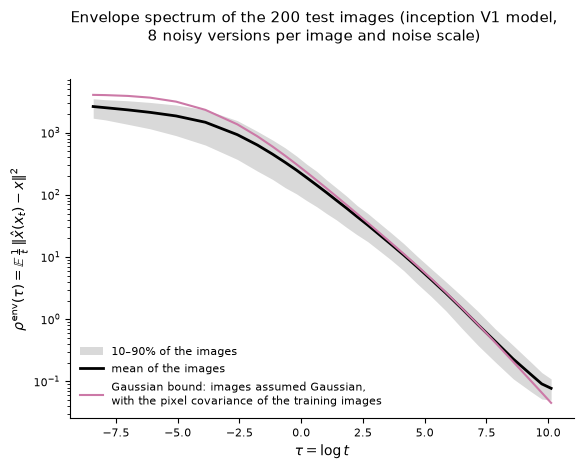

In [7]:
%%time

# 1. the figure, also saved
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
fig, plotted = plot_env_spectrum(spectra, gaussian, PARAMS)
fig.savefig(
    figure_dir / "envelope_spectrum.png", dpi=PARAMS["file_dpi"], bbox_inches="tight"
)

# 2. the values at the finest and coarsest noise scales, against the Gaussian bound
# and its two limits, the number of pixels P and tr C / t
log_t, v1, bound = plotted["log_t"], plotted["mean"], plotted["gaussian"]
coarse_limit = (variances.sum() / spectra["V1"].log_tau.double().exp()).numpy()
for level in (0, -1):
    print(
        f"tau = {log_t[level]:5.2f}: V1 model {v1[level]:8.2f}, Gaussian bound"
        f" {bound[level]:8.2f}, P = {len(variances)},"
        f" tr C / t = {coarse_limit[level]:.3g}"
    )

# 3. the learned curve over the Gaussian bound, and the two models against each other
ratio = v1 / bound
print(f"V1 / Gaussian: min {ratio.min():.2f} at tau = {log_t[ratio.argmin()]:.1f}")
print("levels above the bound: tau =", log_t[ratio > 1].round(1))
gap = abs(spectra["V4"].values.double().mean(dim=0).numpy() / v1 - 1)
print(
    f"V4 vs V1: largest difference {gap.max():.3f} at tau = {log_t[gap.argmax()]:.1f}"
)

## 7. Conclusion

* **What we computed.** The envelope spectrum $\rho^{\rm env}(\tau)$ of the 200 test images at 31 noise levels ($\tau = \log t$ from −8.4 to 10.1), from the null tokens of the inception V1 and V4 diffusion models (8 noisy versions per image and level, about a minute per model), with the Gaussian bound of the training images. The figure is in `assets/figures/task3/`.
* **The shape of the curve.** It falls by more than four orders of magnitude, from 2624 at the finest level to 0.08 at the coarsest, close to the Gaussian bound at coarse levels and well below it at fine ones. The test images differ by a factor of 2 to 4 (10–90% band) at every level.
* **The learned prior beats any linear denoiser at fine scales.** The curve is 0.58 times the Gaussian bound at its lowest ($\tau = -6.1$), and still 0.65 times at the finest level, where it is 2624 against a bound of 4040 and 4096 pixels: even noise that small is a third removed, which no linear denoiser can do. The images are more predictable at fine scales than a Gaussian with their covariance, likely from their non-Gaussian structure (edges, flat regions) and from the JPEG compression of TinyImageNet. Towards coarse levels the ratio rises to 0.96–0.99 ($\tau$ = 4.7 to 7.2): coarse structure is nearly Gaussian.
* **At the coarsest levels the curve measures the network, not the images.** For $\tau \ge 7.9$ it lies above the Gaussian bound (1.04 to 1.71 times), which no exact posterior mean can do: it flattens near 0.08 instead of falling like $\mathrm{tr}\,C/t$ (0.046 at $\tau = 10.1$), an error of the noise prediction of a few hundredths summed over the 4096 pixels. Anything computed from the same network there, such as $\rho(\tau)$ of task 4, inherits that floor.
* **Both models learned the same image statistics.** The null tokens of the V1 and V4 models give curves within 0.3% of each other up to $\tau = 7.2$, and within 2.8% at the coarsest level. This settles the open point of notebook 8, which used the V1 model only.
* **Next steps.** Task 4: the coding spectrum $\rho(\tau) = \rho^{\rm env}(\tau) - \mathbb{E}\left[\frac1t \lVert \hat x(x_t, r) - x \rVert^2\right]$ for V1 and V4, from stimulus–response pairs, drawn under this curve, and $\tfrac12 \int \rho\, d\tau = I(R; X)$. Unlike $\rho^{\rm env}$, it should go to zero at both ends.